In [24]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 

In [25]:
df = pd.read_csv("../data/historical_data.csv", 
                 parse_dates=["created_at", "actual_delivery_time"])

In [26]:
df.shape

(197428, 16)

In [27]:
df.head()

,market_id,created_at,actual_delivery_time,store_id,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_order_place_duration,estimated_store_to_consumer_driving_duration
0,1.0,2015-02-06 22:24:17,2015-02-06 23:27:16,1845,american,1.0,4,3441,4,557,1239,33.0,14.0,21.0,446,861.0
1,2.0,2015-02-10 21:49:25,2015-02-10 22:56:29,5477,mexican,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,446,690.0
2,3.0,2015-01-22 20:39:28,2015-01-22 21:09:09,5477,NaN,1.0,1,1900,1,1900,1900,1.0,0.0,0.0,446,690.0
3,3.0,2015-02-03 21:21:45,2015-02-03 22:13:00,5477,NaN,1.0,6,6900,5,600,1800,1.0,1.0,2.0,446,289.0
4,3.0,2015-02-15 02:40:36,2015-02-15 03:20:26,5477,NaN,1.0,3,3900,3,1100,1600,6.0,6.0,9.0,446,650.0


In [28]:
df.dtypes

market_id                                              float64
created_at                                      datetime64[us]
actual_delivery_time                            datetime64[us]
store_id                                                 int64
store_primary_category                                     str
order_protocol                                         float64
total_items                                              int64
subtotal                                                 int64
num_distinct_items                                       int64
min_item_price                                           int64
max_item_price                                           int64
total_onshift_dashers                                  float64
total_busy_dashers                                     float64
total_outstanding_orders                               float64
estimated_order_place_duration                           int64
estimated_store_to_consumer_driving_duration           

In [29]:
df["duration"] = (df["actual_delivery_time"] - df["created_at"]).dt.total_seconds()
print(df["duration"].head(2))

0    3779.0
1    4024.0
Name: duration, dtype: float64


store_primary_category is NaN in rows 2–4, yet row 1 shows store 5477 as mexican. So a store’s missing category can often be recovered from its other rows.

created_at is UTC, and the stores are in US/Pacific. We’ll convert before extracting hour or weekday

In [30]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage":df.isna().sum().div(len(df)).mul(100)
})


missing = missing.sort_values(
    "missing_percentage", ascending=False
)

display(missing)

,missing_count,missing_percentage
total_onshift_dashers,16262,8.236927
total_busy_dashers,16262,8.236927
total_outstanding_orders,16262,8.236927
store_primary_category,4760,2.411006
order_protocol,995,0.503981
market_id,987,0.499929
estimated_store_to_consumer_driving_duration,526,0.266426
actual_delivery_time,7,0.003546
duration,7,0.003546
num_distinct_items,0,0.000000


In [31]:
display(df["duration"].describe())

percentiles = df["duration"].quantile([0.90, 0.99, 0.999])

print("\nTarget percentiles:")
print(percentiles)

print("\nMaximum duration:", df["duration"].max())

count    1.974210e+05
mean     2.908257e+03
std      1.922961e+04
min      1.010000e+02
25%      2.104000e+03
50%      2.660000e+03
75%      3.381000e+03
max      8.516859e+06
Name: duration, dtype: float64


Target percentiles:
0.900    4235.00
0.990    6474.80
0.999    9934.86
Name: duration, dtype: float64

Maximum duration: 8516859.0


In [32]:
# Ten largest delivery duration
display(df["duration"].nlargest(10))

#Count extreme and unusually short deliveries 
thresholds = {
    "Over 3 hours" : 3 * 60 * 60,
    "Over 6 hours" : 6 * 60 * 60,
    "Over 24 hours" : 24 * 60 * 60,
    "Under 5 minutes" : 5 * 60
}


for label, seconds in thresholds.items():
    if label == "Under 5 minutes":
        count = (df["duration"] < seconds).sum()
    else:
        count = (df["duration"] > seconds).sum()
        
    print(f"{label}: {count:,}")

2690      8516859.0
185550     373879.0
27189      332482.0
83055       57032.0
190860      54447.0
86952       48178.0
76743       45685.0
105825      39352.0
66787       38457.0
175971      38143.0
Name: duration, dtype: float64

Over 3 hours: 138
Over 6 hours: 25
Over 24 hours: 3
Under 5 minutes: 3


Observation: The corrected threshold counts show 138 deliveries over 3 hours, 25 over 6 hours, and 3 over 24 hours; only 3 durations are under 5 minutes. The largest recorded duration is 8,516,859 seconds (about 98.6 days), which is implausible for an ordinary food delivery and warrants record-level investigation. These results flag potential anomalies; no cutoff is selected in this EDA cell.

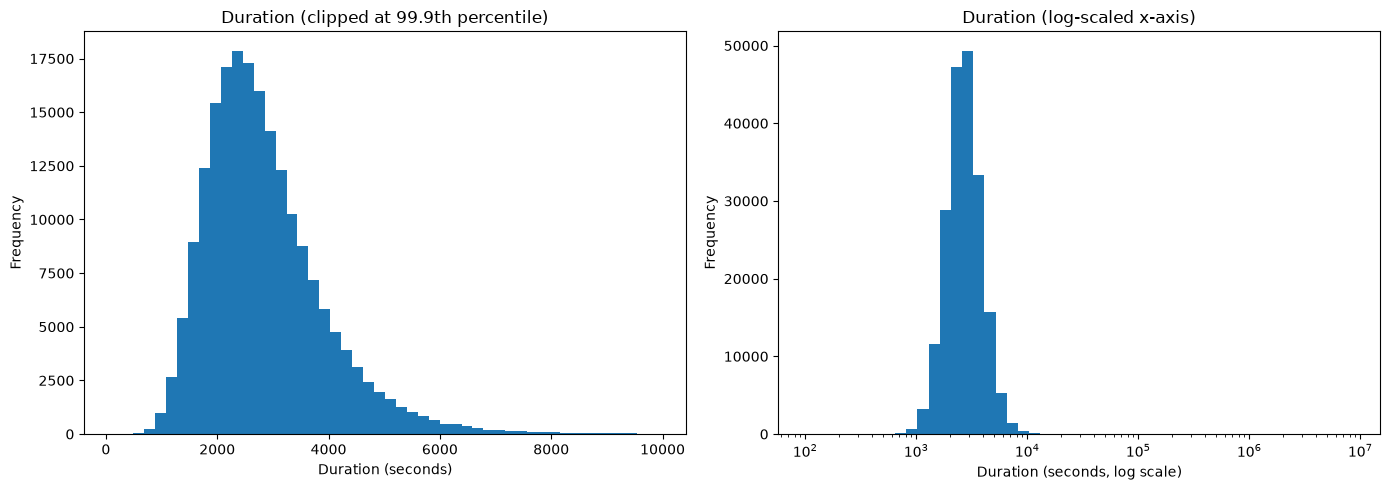

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#Clip the upper tail at the 99.9th percentile for visualization
upper = df["duration"].quantile(0.999)
clipped = df.loc[df["duration"] <= upper, "duration"].dropna()

axes[0].hist(clipped, bins=50)
axes[0].set_title("Duration (clipped at 99.9th percentile)")
axes[0].set_xlabel("Duration (seconds)")
axes[0].set_ylabel("Frequency")

#Log-scaled x-axis: only positive durations are valid
positive = df.loc[
    df["duration"] > 0, "duration"
].dropna()

log_bins = np.logspace(
    np.log10(positive.min()),
    np.log10(positive.max()),
    50
)


axes[1].hist(positive, bins=log_bins)
axes[1].set_xscale("log")
axes[1].set_title("Duration (log-scaled x-axis)")
axes[1].set_xlabel("Duration (seconds, log scale)")
axes[1].set_ylabel("Frequency")


plt.tight_layout()
plt.show()

Observation: The clipped histogram makes the main duration distribution easier to inspect, while logarithmically spaced bins on the log-scaled histogram show a wider range of positive durations. The target is right-skewed with a long upper tail. The clipping is for visualization only; it does not remove rows from df.

In [34]:

numeric_summary = df.select_dtypes(
    include="number"
).describe().T

display(numeric_summary)

print("Columns with negative minimum values:")

negative_minimums = numeric_summary.loc[
    numeric_summary["min"] < 0,
    ["min"]
]

display(negative_minimums)


,count,mean,std,min,25%,50%,75%,max
market_id,196441.0,2.978706,1.524867,1.0,2.0,3.0,4.0,6.0
store_id,197428.0,3530.510272,2053.496711,1.0,1686.0,3592.0,5299.0,6987.0
order_protocol,196433.0,2.882352,1.503771,1.0,1.0,3.0,4.0,7.0
total_items,197428.0,3.196391,2.666546,1.0,2.0,3.0,4.0,411.0
subtotal,197428.0,2682.331402,1823.093688,0.0,1400.0,2200.0,3395.0,27100.0
num_distinct_items,197428.0,2.670791,1.630255,1.0,1.0,2.0,3.0,20.0
min_item_price,197428.0,686.218470,522.038648,-86.0,299.0,595.0,949.0,14700.0
max_item_price,197428.0,1159.588630,558.411377,0.0,800.0,1095.0,1395.0,14700.0
total_onshift_dashers,181166.0,44.808093,34.526783,-4.0,17.0,37.0,65.0,171.0
total_busy_dashers,181166.0,41.739747,32.145733,-5.0,15.0,34.0,62.0,154.0


Columns with negative minimum values:


,min
min_item_price,-86.0
total_onshift_dashers,-4.0
total_busy_dashers,-5.0
total_outstanding_orders,-6.0


Observation: The numeric summary shows negative minimums for min_item_price (-86), total_onshift_dashers (-4), total_busy_dashers (-5), and total_outstanding_orders (-6). These values are inconsistent with ordinary prices and counts. Inspect the affected records before setting invalid values to missing in Phase 2; this EDA cell does not alter the source data

In [35]:

conditions = {
    "Negative min_item_price":
        df["min_item_price"] < 0,

    "Negative total_onshift_dashers":
        df["total_onshift_dashers"] < 0,

    "Negative total_busy_dashers":
        df["total_busy_dashers"] < 0,

    "Negative total_outstanding_orders":
        df["total_outstanding_orders"] < 0,

    "Busy dashers > on-shift dashers":
        df["total_busy_dashers"] > df["total_onshift_dashers"],

    "min_item_price > max_item_price":
        df["min_item_price"] > df["max_item_price"]
}

for label, condition in conditions.items():
    print(f"{label}: {condition.sum():,}")


Negative min_item_price: 13
Negative total_onshift_dashers: 21
Negative total_busy_dashers: 21
Negative total_outstanding_orders: 44
Busy dashers > on-shift dashers: 40,394
min_item_price > max_item_price: 800


Observation: The audit found 13 negative min_item_price values, 21 negative total_onshift_dashers values, 21 negative total_busy_dashers values, and 44 negative total_outstanding_orders values. Busy dashers exceed on-shift dashers in 40,394 rows, and min_item_price exceeds max_item_price in 800 rows. The conditions can overlap, so these counts are not counts of unique affected rows. Investigate definitions and records before choosing a treatment.

In [36]:
dasher_cols = [
    "total_onshift_dashers",
    "total_busy_dashers",
    "total_outstanding_orders"
]

missing_masks = df[dasher_cols].isna()

print("All three missing:",
      missing_masks.all(axis=1).sum())

print("Any missing:",
      missing_masks.any(axis=1).sum())

print("Identical missingness patterns:",
      missing_masks.nunique(axis=1).eq(1).all())

All three missing: 16262
Any missing: 16262
Identical missingness patterns: True


Observation: All three dasher columns are missing together in 16,262 rows (about 8.2% of the dataset), and the number of rows with any missing value in these three columns is also 16,262. Their missingness masks match across all rows. This is block missingness; it may reflect a shared operational-data gap, but the pattern alone does not establish the cause.

In [37]:

# Number of distinct stores
print("Unique stores:", df["store_id"].nunique())

# Frequency of orders per store
store_counts = df["store_id"].value_counts()

print("Stores appearing once:", (store_counts == 1).sum())
print("Stores appearing twice:", (store_counts == 2).sum())

# Exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())


Unique stores: 6743
Stores appearing once: 566
Stores appearing twice: 477
Exact duplicate rows: 0


Observation: The dataset contains 6,743 unique stores. There are 566 stores with one row and 477 with two rows (1,043 stores, about 15.5%, represented by only one or two records). Store-level statistics or encodings should account for sparse history, for example through smoothing and a fallback for unseen stores. No exact duplicate rows were detected; this does not rule out duplicate orders that differ in some fields

In [38]:
for col in [
    "total_onshift_dashers",
    "total_busy_dashers",
    "total_outstanding_orders"
]:
    print(f"\n{col}")
    print(
        df.loc[df[col] < 0, col]
        .value_counts()
        .sort_index()
    )


total_onshift_dashers
total_onshift_dashers
-4.0     1
-3.0     1
-2.0    13
-1.0     6
Name: count, dtype: int64

total_busy_dashers
total_busy_dashers
-5.0     1
-4.0     2
-3.0     2
-2.0     3
-1.0    13
Name: count, dtype: int64

total_outstanding_orders
total_outstanding_orders
-6.0     5
-5.0     6
-4.0     3
-3.0     8
-2.0     6
-1.0    16
Name: count, dtype: int64


In [39]:
category_by_store = (
    df.groupby("store_id")["store_primary_category"]
    .agg(
        observed_categories="nunique",
        has_category=lambda s: s.notna().any()
    )
)

missing_category = df["store_primary_category"].isna()

recoverable = (
    df.loc[missing_category, "store_id"]
    .map(category_by_store["has_category"])
    .fillna(False)
)

print("Missing category rows:", missing_category.sum())
print("Rows with category recoverable from store:",
      recoverable.sum())
print("Rows without an observed category for that store:",
      (~recoverable).sum())

print("Stores with conflicting observed categories:",
      (category_by_store["observed_categories"] > 1).sum())

Missing category rows: 4760
Rows with category recoverable from store: 3893
Rows without an observed category for that store: 867
Stores with conflicting observed categories: 3001


In [40]:
checks = {
    "subtotal == 0": df["subtotal"] == 0,
    "total_items > 50": df["total_items"] > 50,
    "estimated_order_place_duration == 0":
        df["estimated_order_place_duration"] == 0,
    "estimated_store_to_consumer_driving_duration == 0":
        df["estimated_store_to_consumer_driving_duration"] == 0,
}

for label, mask in checks.items():
    print(f"{label}: {mask.sum():,}")

subtotal == 0: 179
total_items > 50: 8
estimated_order_place_duration == 0: 94
estimated_store_to_consumer_driving_duration == 0: 9


In [41]:

# Category agreement within stores

store_col = "store_id"
category_col = "store_primary_category"

# Use only rows with a known store and category
known = df.dropna(subset=[store_col, category_col]).copy()

# Identify stores with multiple distinct recorded categories
category_counts = known.groupby(store_col)[category_col].nunique()
conflicting_stores = category_counts[category_counts > 1].index

# Find each store's most common category
store_modes = (
    known.groupby(store_col)[category_col]
    .agg(lambda s: s.value_counts().idxmax())
)

# Compare each observed category with its store's most common category
known["store_mode"] = known[store_col].map(store_modes)
known["agrees_with_mode"] = (
    known[category_col] == known["store_mode"]
)

# Overall agreement among rows with known categories
overall_agreement = known["agrees_with_mode"].mean()

# Agreement among rows belonging to conflicting stores only
conflict_rows = known[known[store_col].isin(conflicting_stores)]
conflict_agreement = conflict_rows["agrees_with_mode"].mean()

print(f"Stores analyzed: {category_counts.size:,}")
print(f"Stores with conflicting categories: {len(conflicting_stores):,}")
print(f"Overall row-level agreement: {overall_agreement:.2%}")
print(f"Conflicting-store row-level agreement: {conflict_agreement:.2%}")


Stores analyzed: 6,569
Stores with conflicting categories: 3,001
Overall row-level agreement: 95.41%
Conflicting-store row-level agreement: 94.57%


In [42]:
# A. Reversed prices: min_item_price > max_item_price
reversed_prices = df[df["min_item_price"] > df["max_item_price"]].copy()
print(f"Rows affected: {len(reversed_prices):,}")

gap = reversed_prices["min_item_price"] - reversed_prices["max_item_price"]
print("\nGap (min - max), in cents:")
print(gap.describe())

print("\nShare of reversed rows by num_distinct_items (%):")
print(
    reversed_prices["num_distinct_items"]
    .value_counts(normalize=True)
    .sort_index()
    .head(6)
    .mul(100)
    .round(2)
)

# Single-distinct-item orders: compare the implied unit price with each recorded price
single = reversed_prices[reversed_prices["num_distinct_items"] == 1].copy()
print(f"\nSingle-distinct-item reversed rows: {len(single):,}")

if len(single) > 0:
    single["unit_price"] = single["subtotal"] / single["total_items"]
    single["err_vs_min"] = (single["unit_price"] - single["min_item_price"]).abs()
    single["err_vs_max"] = (single["unit_price"] - single["max_item_price"]).abs()

    print("\nAbsolute error of implied unit price (cents):")
    print(single[["err_vs_min", "err_vs_max"]].describe())

    closer_to_max = (single["err_vs_max"] < single["err_vs_min"]).mean()
    print(f"\nShare where recorded max is closer to the implied price: {closer_to_max:.2%}")

print("\nExample reversed rows:")
print(
    reversed_prices[
        ["min_item_price", "max_item_price", "num_distinct_items", "total_items", "subtotal"]
    ].head(5)
)

Rows affected: 800

Gap (min - max), in cents:
count    800.00000
mean      46.00875
std       38.00377
min        1.00000
25%       16.00000
50%       37.00000
75%       67.00000
max      198.00000
dtype: float64

Share of reversed rows by num_distinct_items (%):
num_distinct_items
1    83.62
2    13.63
3     1.75
4     0.62
5     0.25
7     0.12
Name: proportion, dtype: float64

Single-distinct-item reversed rows: 669

Absolute error of implied unit price (cents):
        err_vs_min   err_vs_max
count   669.000000   669.000000
mean    287.461667   323.299983
std     285.783397   295.882057
min       0.500000     2.000000
25%      89.000000   115.500000
50%     217.000000   257.000000
75%     382.000000   429.000000
max    3072.000000  3058.000000

Share where recorded max is closer to the implied price: 11.51%

Example reversed rows:
      min_item_price  max_item_price  num_distinct_items  total_items  \
166              889             772                   2            2   
273   

In [43]:
# B. subtotal == 0
zero_subtotal = df[df["subtotal"] == 0].copy()
print(f"Rows affected: {len(zero_subtotal):,}")

print("\nCondition counts:")
print(pd.Series({
    "Both prices == 0": (
        (zero_subtotal["min_item_price"] == 0)
        & (zero_subtotal["max_item_price"] == 0)
    ).sum(),
    "Any price < 0": (
        (zero_subtotal["min_item_price"] < 0)
        | (zero_subtotal["max_item_price"] < 0)
    ).sum(),
    "Any price > 0": (
        (zero_subtotal["min_item_price"] > 0)
        | (zero_subtotal["max_item_price"] > 0)
    ).sum(),
    "total_items >= 1": (zero_subtotal["total_items"] >= 1).sum(),
}))

print(
    f"\nMedian duration: zero-subtotal rows = {zero_subtotal['duration'].median():,.0f}s, "
    f"all rows = {df['duration'].median():,.0f}s"
)

print("\nExample rows:")
print(
    zero_subtotal[
        ["min_item_price", "max_item_price", "total_items", "num_distinct_items", "duration"]
    ].head(5)
)

Rows affected: 179

Condition counts:
Both prices == 0      0
Any price < 0         0
Any price > 0       179
total_items >= 1    179
dtype: int64

Median duration: zero-subtotal rows = 2,763s, all rows = 2,660s

Example rows:
      min_item_price  max_item_price  total_items  num_distinct_items  \
1070             295            1225            7                   7   
1837             169             200            5                   2   
3947             405            1395            2                   2   
4240            1495            1495            1                   1   
7035             995            1295            3                   3   

      duration  
1070    2068.0  
1837    1800.0  
3947    1412.0  
4240    2029.0  
7035    2916.0  


In [44]:
# C. total_items > 50
high_items = df[df["total_items"] > 50]
print(f"Rows affected: {len(high_items):,}\n")
print(
    high_items[
        ["total_items", "num_distinct_items", "subtotal",
         "min_item_price", "max_item_price", "duration"]
    ]
)

Rows affected: 8

        total_items  num_distinct_items  subtotal  min_item_price  \
11055            56                   7      2317               0   
15053            57                   5       858               0   
47231           411                   5      3115               0   
75577            59                   3      2911               0   
105348           51                   4      1343               0   
182223           84                   4      1016               0   
182796           64                   4      1166               0   
182800           66                   6      1634               0   

        max_item_price  duration  
11055              289    2920.0  
15053              229    2346.0  
47231              299    3055.0  
75577              329    2085.0  
105348             169    4197.0  
182223             289    4478.0  
182796             499    1736.0  
182800             499    1762.0  


In [45]:
print(f"Conflicting stores: {len(conflicting_stores) / category_counts.size:.2%}")

Conflicting stores: 45.68%


| Anomaly | Rows | Treatment (Phase 2) | Evidence |
|---|---:|---|---|
| Missing target | 7 | Drop | No label to train or evaluate on |
| Duration > 3 h | 138 | Drop | 0.07% of data; max 98 days; 99.9th percentile is 2.8 h |
| Duration < 5 min | 3 | Drop | Minimum is 101 s, too short for prep plus driving |
| Negative dasher / order counts | 21 / 21 / 44 | Set to `NaN` | Values -1 to -6, no sentinel pattern |
| Negative `min_item_price` | 13 | Set to `NaN` | Invalid price |
| `min_item_price` > `max_item_price` | 800 | Set both to `NaN` | Median gap 37¢; subtotal cannot verify a swap |
| Busy > on-shift dashers | 40,394 | Keep; handle in features | 20% of rows; clip available dashers at 0 |
| `subtotal == 0` | 179 | Set subtotal to `NaN`, keep row | Prices > 0, items ≥ 1, normal durations |
| `total_items > 50` | 8 | Drop | Corrupt counts, all with minimum price 0 |
| Estimate equals 0 | 94 / 9 | Keep and flag | May be a real estimation behavior |
| Dasher block missing | 16,262 | Keep `NaN` + missing flag | Block missingness |
| Missing market / protocol / driving estimate | 987 / 995 / 526 | Keep `NaN`; impute in pipeline for linear models | Under 0.5% each |
| Missing category | 4,760 | Store mode (3,893), otherwise `"unknown"` (867) | 94.57% agreement within conflicting stores |
| Sparse stores | 1,043 with ≤ 2 rows | Smooth encoding in Phase 3 | No cleaning needed |